# plot regional reversibility relative to the global average

In [7]:
%load_ext autoreload
%autoreload 2
    
import xarray as xr
import numpy as np
from dask.distributed import Client
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
import matplotlib.gridspec as gridspec
from matplotlib.colors import ListedColormap, BoundaryNorm, TwoSlopeNorm, CenteredNorm
import matplotlib.cm as cm
import warnings
warnings.filterwarnings('ignore')

from cdrmip_extremes import utils, stats, plotting
from cdrmip_extremes.load_processed import load_processed, load_scalar_outputs
from cdrmip_extremes.configs import cdr_colour_dict, CDR_MODELS, PROC_DIR, FIG_DIR

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

In [3]:
gsat = load_processed(PROC_DIR, 'CDRMIP', 'gsat', model_order=CDR_MODELS)
gsat_rolling = load_processed(PROC_DIR, 'CDRMIP', 'gsat_rolling', model_order=CDR_MODELS)

In [4]:
tas_data = load_processed(PROC_DIR, 'CDRMIP','tas',category='anomalies',model_order=CDR_MODELS)

In [5]:
CO2 = utils.build_co2_path()

### Regional Reversibility Relative to the Global Average
Here we want to create a map of peak warming relative to the CO2 peak (year 140) (i.e. how many years post peak warming does the peak come?) and with a divergent colormap centred on the gsat peak (i.e. red will indicate the local peak is after peak GSAT and blue indicates the local peak precedes peak GSAT).

<br>
So first step is to calculate local peak warming

In [6]:
peak_years = {}
for model, expt_dt in tas_data.items():
    for expt, member_dt in expt_dt.items():
        for member, ds in member_dt.items():
            da = stats._rolling_mean(ds.tas,21,time_dim='year')
            peak_year = ds.tas.idxmax(dim='year')
            peak = ds.sel({'year':peak_year})
            peak_years[model] = {expt:peak_year}

peak_years = stats.reduce_models(peak_years)
peak_gsat = utils.flatten_single(
    load_scalar_outputs(PROC_DIR,'CDRMIP','peak_warming')
)

In [10]:
data_copy = peak_gsat.copy()
median_year = int(np.median([data_copy[model]['peak_year'] for model in data_copy.keys()]))
median_peak = np.median([data_copy[model]['peak'] for model in data_copy.keys()])
peak_gsat['multi_model_median'] = {'peak':median_peak,'peak_year':median_year}

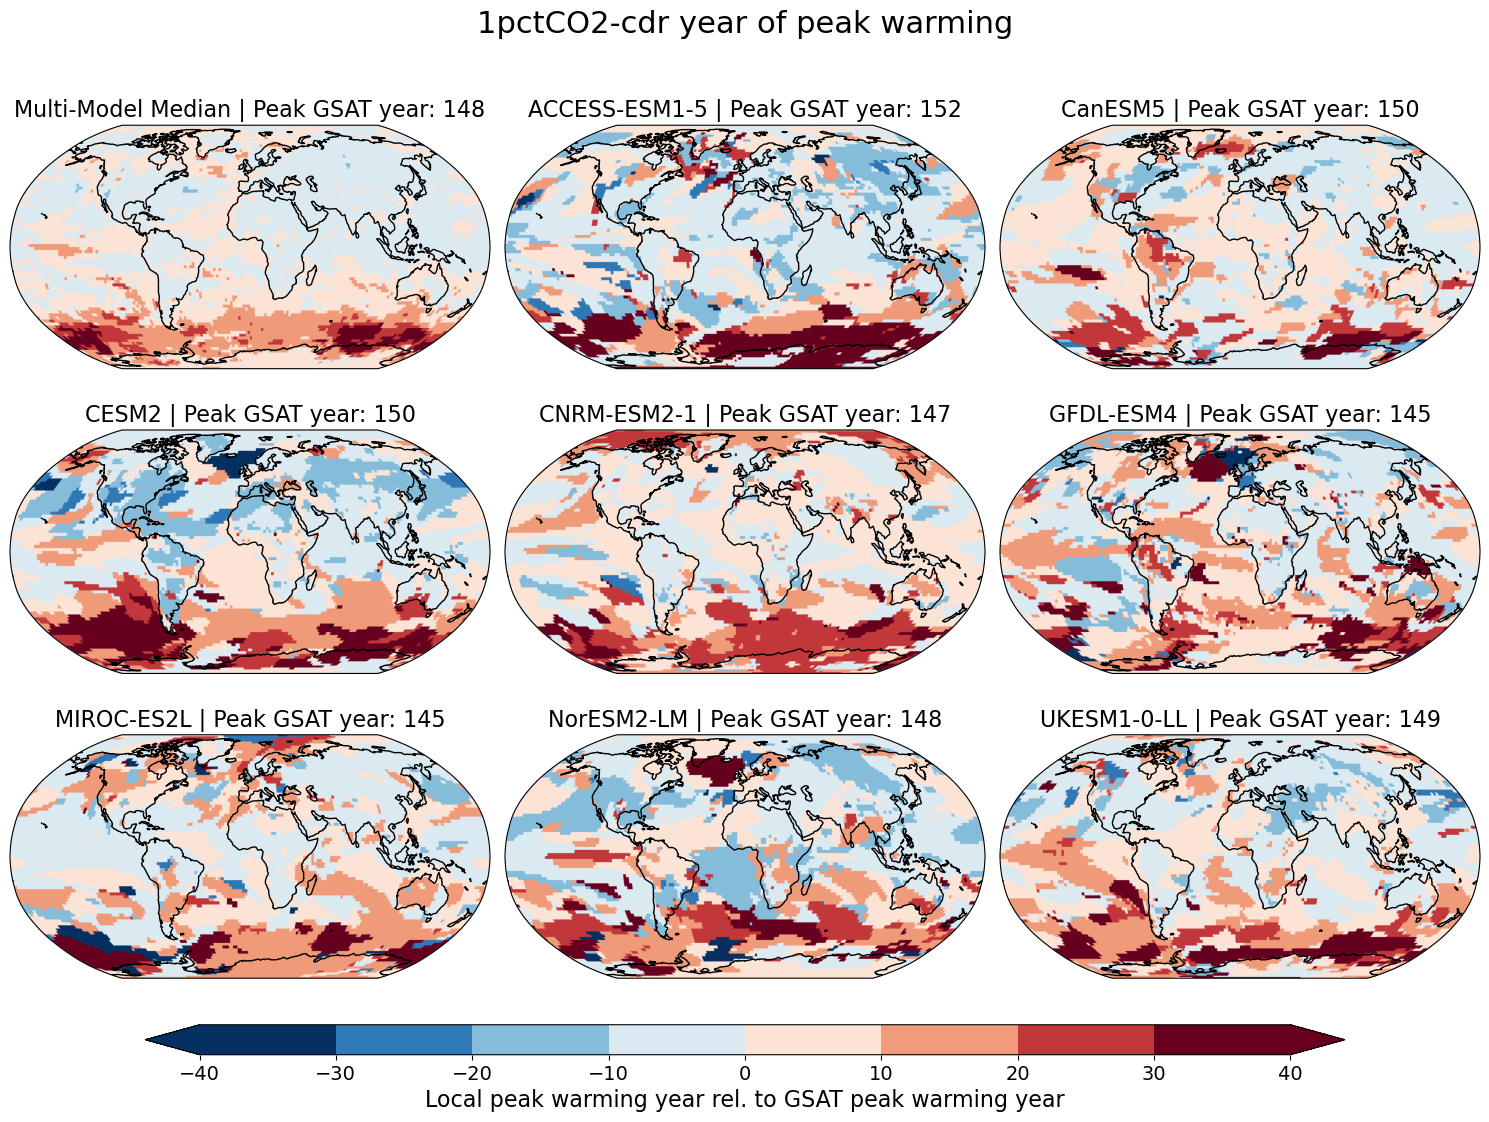

In [11]:
fig = plotting.plot_peak_warming_years(
    peak_years,
    peak_gsat,
    expt='1pctCO2-cdr',
    levels = np.arange(-40,41,10),
    fig_dir=FIG_DIR,folder='supplementary',file_name='figure_S5.jpg'
)

## Reversibility map at same co2 level (let's say half way down/up, year 70 vs 210)

In [12]:
# make timeseries
reversibility = {}
for model, expt_dt in tas_data.items():
    for expt, member_dt in expt_dt.items():
        for member, ds in member_dt.items():
            da = stats._rolling_mean(ds.tas,21,time_dim='year')
            pre = da.sel(year=slice(0,140))
            post = da.sel(year=slice(140,280)).assign_coords({'year':pre.year[::-1]})
            reversibility[model] = {expt: post - pre}

reversibility_gsat = {}
for model, expt_dt in gsat_rolling.items():
    for expt, ds in expt_dt.items():
        da = ds.gsat_rolling
        pre = da.sel(year=slice(0,140))
        post = da.sel(year=slice(140,280)).assign_coords({'year':pre.year[::-1]})
        reversibility_gsat[model] = {expt: (post - pre)}

In [13]:
reversibility = stats.reduce_models(reversibility)
reversibility_gsat = stats.reduce_models(reversibility_gsat)

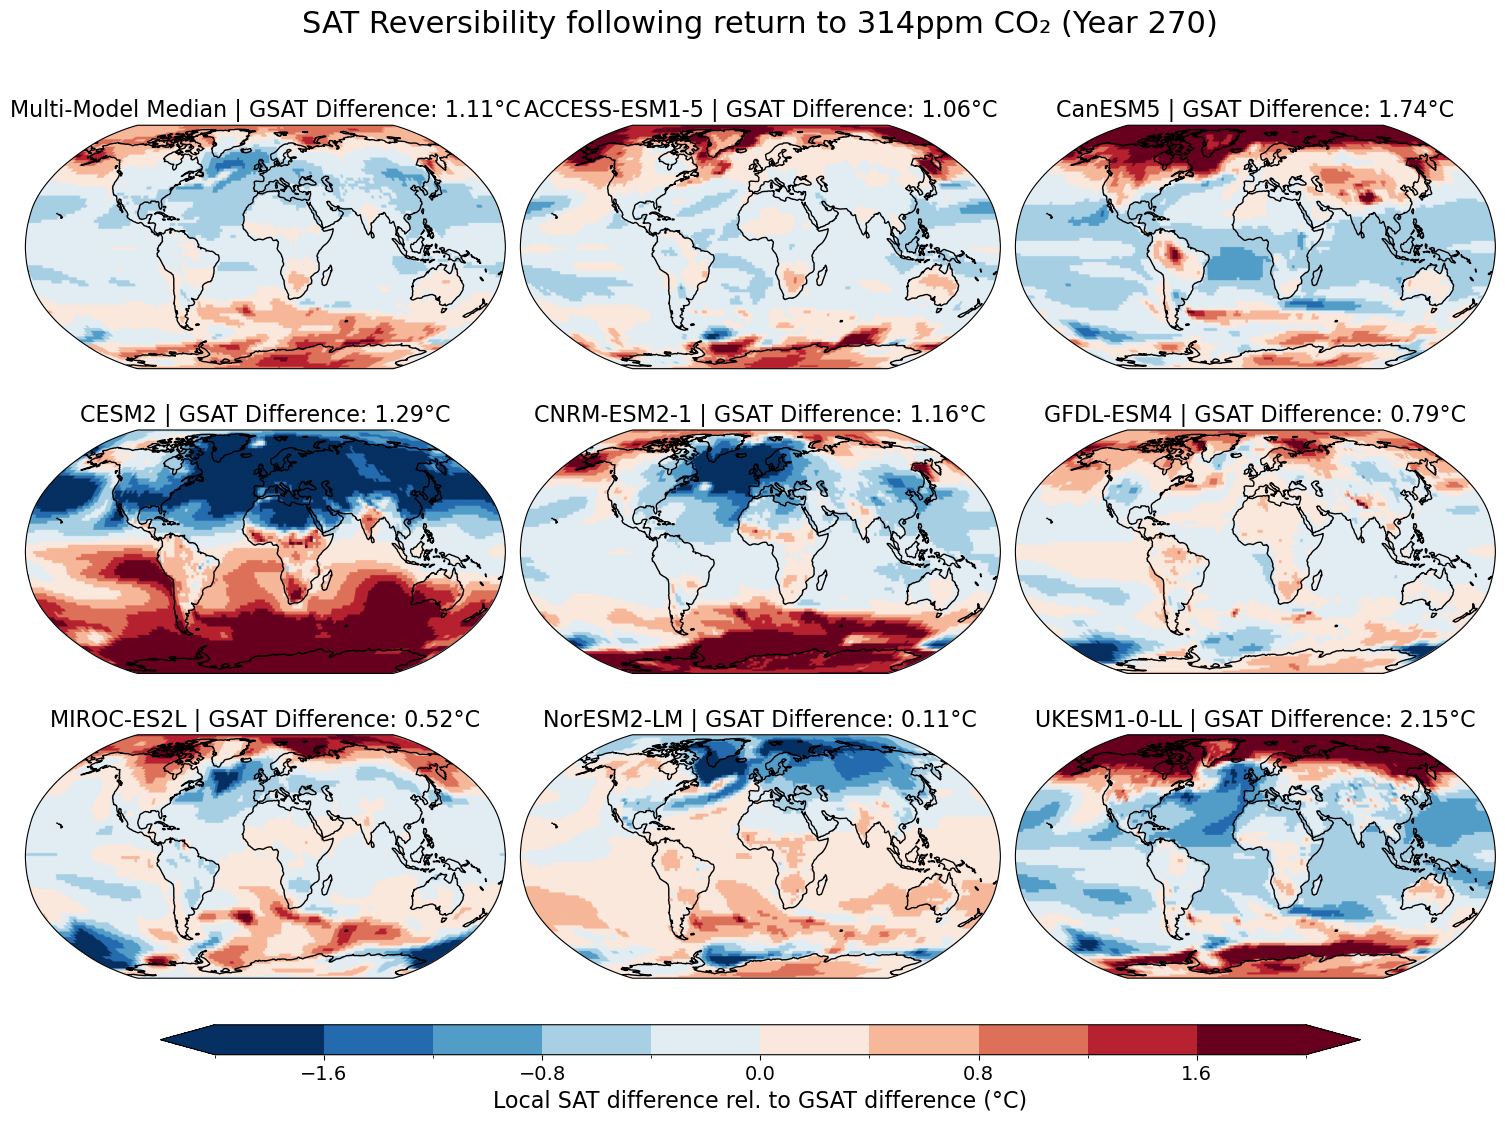

In [16]:
fig = plotting.plot_reversibility_rel_gsat_normalised(
    reversibility,
    reversibility_gsat,
    window=2,
    bins=11,
    rev_year=10,
    expt='1pctCO2-cdr',
    CO2=CO2
)

fig.savefig(
    FIG_DIR / "supplementary" / "figure_S7.jpg",
    dpi=300,
    bbox_inches="tight",
    pil_kwargs={"quality": 95}
)

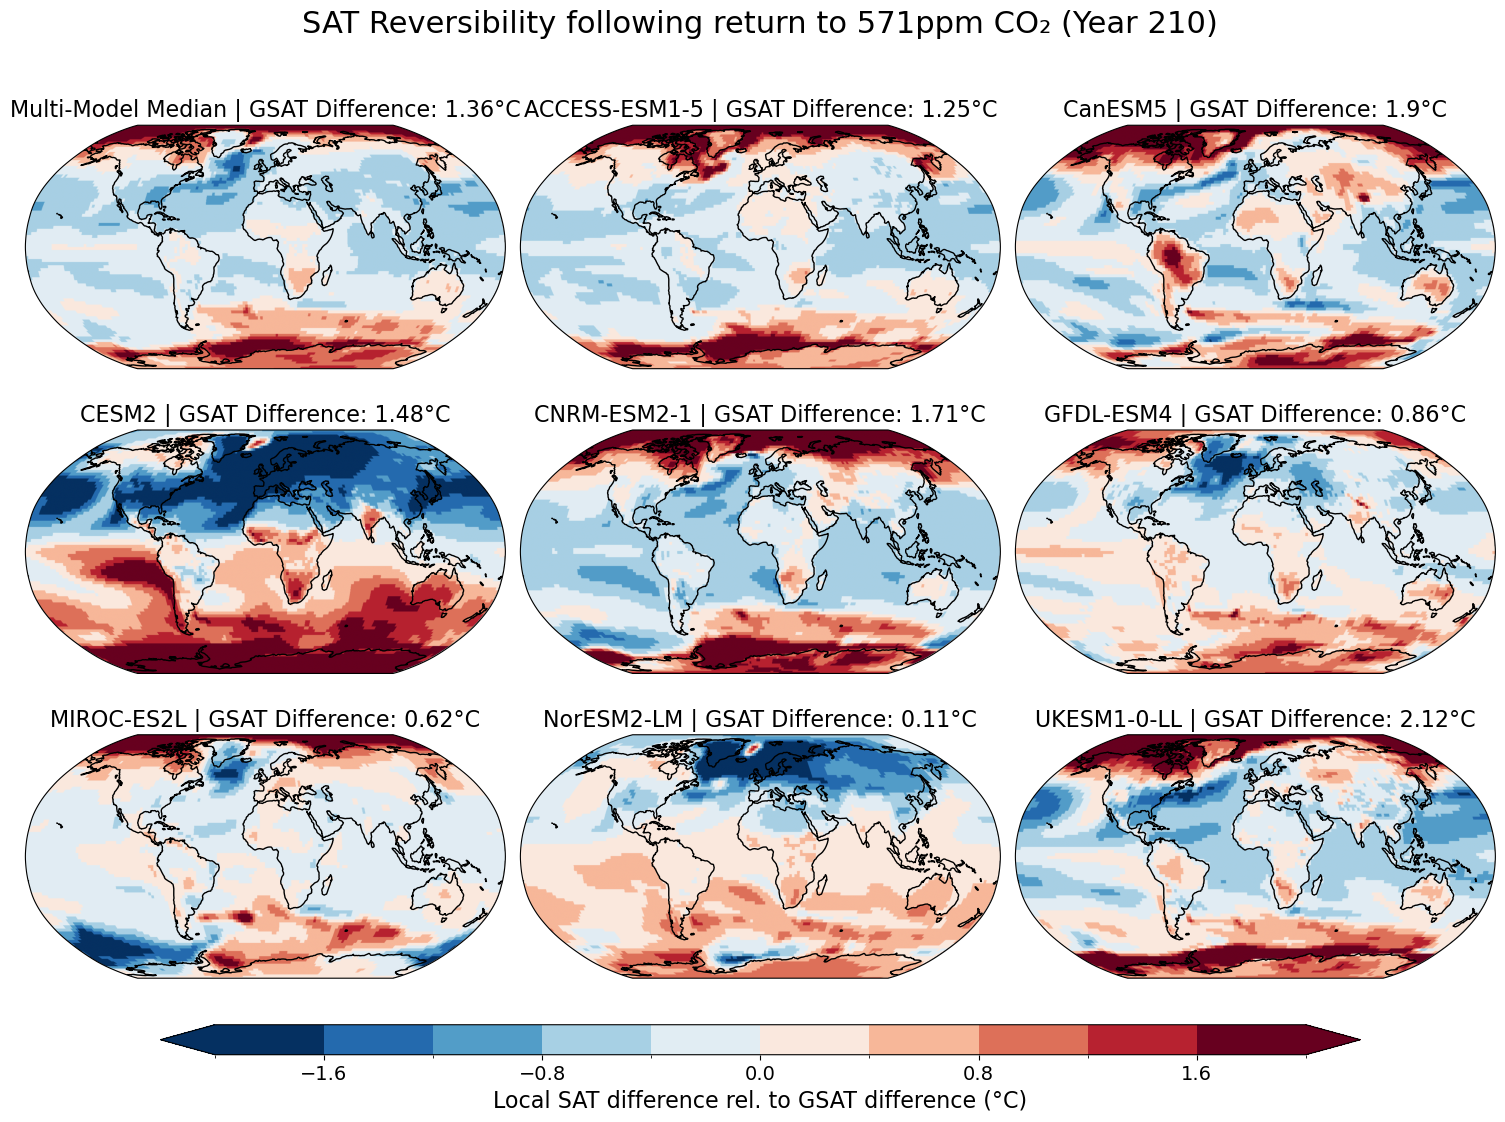

In [18]:
fig = plotting.plot_reversibility_rel_gsat_normalised(
    reversibility,
    reversibility_gsat,
    window=2,
    bins=11,
    rev_year=70,
    expt='1pctCO2-cdr',
    CO2=CO2
)

fig.savefig(
    FIG_DIR / "supplementary" / "figure_S6.jpg",
    dpi=300,
    bbox_inches="tight",
    pil_kwargs={"quality": 95}
)